[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/roberthsu2003/PythonForDataAnalysis/blob/master/%E8%B3%87%E6%96%99%E6%95%B4%E7%90%86%E5%92%8C%E4%BD%BF%E7%94%A8%E5%89%8D%E6%BA%96%E5%82%99/%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90/%E7%AF%84%E4%BE%8B_%E6%AD%BB%E4%BA%A1%E8%BB%8A%E7%A6%8D%E8%B3%87%E6%96%99%E5%A4%A7%E6%8E%83%E9%99%A4_A1%E4%BA%A4%E9%80%9A%E4%BA%8B%E6%95%85.ipynb)

# 🚦 死亡車禍資料大掃除：清理警政署 A1 交通事故

> 🎯 **情境**：台灣每年有上千人死於車禍。警政署公開了每一件「A1 類」（造成死亡）事故的詳細資料：時間、地點、天氣、車種、年齡、肇事原因……但下載下來你會發現：檔案最後混了說明文字、日期是 `20260101.0`、時間是 `53700.0`、「死亡1;受傷0」擠在同一格，而且**一場車禍會出現好幾列**。今天的任務是：**把它清理乾淨，再回答「死亡車禍最常發生在什麼時候？為什麼會發生？」**

| 素材檔案 | 內容 |
| --- | --- |
| `A1類交通事故.csv` | 警政署 A1 類交通事故（**有人在 24 小時內死亡**的車禍）：今年 1 月起，每一列是一位當事者，共 51 個欄位 |

| 📡 資料來源（政府資料開放平台） | 提供機關 | 下載日期 |
| --- | --- | --- |
| [即時交通事故資料(A1類)](https://data.gov.tw/dataset/12818) | 內政部警政署 | 2026-10-24 |

> ✅ 這些都是**真實的政府開放資料**，依「政府資料開放授權條款－第1版」使用。課堂上統一使用上表日期的快照，所以每個人跑出來的數字都一樣。

> ⚠️ 這份資料記錄的是真實發生、有人過世的事故。分析它的目的，是找出可以預防的原因——**每一個數字背後，都是一個家庭。**

## 🗺️ 今日任務地圖

| 關卡 | 要回答的問題 |
| --- | --- |
| ⬜ 任務 1 | 健康檢查——資料最後面怎麼有奇怪的東西？ |
| ⬜ 任務 2 | 日期是 `20260101.0`、時間是 `53700.0`？——型態轉換 |
| ⬜ 任務 3 | 「死亡1;受傷0」——把一格文字拆成兩個數字 |
| ⬜ 任務 4 | 2,885 列，但其實沒有 2,885 件車禍！ |
| ⬜ 任務 5 | 年齡 -1 歲？——處理異常值與缺值 |
| ⬜ 任務 6 | 清乾淨了！死亡車禍最常發生在什麼時候？為什麼？ |

**怎麼用這本 Notebook**：從上到下按 `Shift + Enter` 一格一格執行。每個任務都會先講「你想知道什麼」，再給程式，最後用 💡 **看懂結果** 告訴你這個數字代表什麼。

In [1]:
# 📦 準備素材：在 Colab 開啟時，自動下載本章素材壓縮檔並解壓縮
#    （若是在自己電腦解壓縮後開啟，檔案已經在旁邊，會直接使用）
import os, zipfile, urllib.request

FILES = [
    'A1類交通事故.csv',
]
ZIP_URL = 'https://github.com/roberthsu2003/PythonForDataAnalysis/raw/master/%E8%B3%87%E6%96%99%E6%95%B4%E7%90%86%E5%92%8C%E4%BD%BF%E7%94%A8%E5%89%8D%E6%BA%96%E5%82%99/%E8%B3%87%E6%96%99%E6%95%B4%E7%90%86%E5%92%8C%E4%BD%BF%E7%94%A8%E5%89%8D%E6%BA%96%E5%82%99_%E5%AD%B8%E7%94%9F%E7%B4%A0%E6%9D%90.zip'

if not all(os.path.exists(f) for f in FILES):
    urllib.request.urlretrieve(ZIP_URL, 'materials.zip')            # 下載本章素材壓縮檔
    with zipfile.ZipFile('materials.zip') as z:
        for name in z.namelist():
            inner = name.split('/', 1)[1] if '/' in name else name   # 去掉壓縮檔最外層的資料夾名稱
            if inner and not name.endswith('/'):
                os.makedirs(os.path.dirname(inner) or '.', exist_ok=True)
                with z.open(name) as src, open(inner, 'wb') as dst:
                    dst.write(src.read())

print('✅ 素材準備完成：', [f for f in FILES if os.path.exists(f)])

✅ 素材準備完成： ['A1類交通事故.csv']


In [ ]:
# --- 設定 Matplotlib 中文字型支援（Mac / Windows / Colab 通用）---
%pip install -q mplfonts

import glob, os
import mplfonts
from matplotlib import font_manager
from mplfonts import use_font

for f in glob.glob(os.path.join(os.path.dirname(mplfonts.__file__), "fonts", "*.[ot]tf")):
    font_manager.fontManager.addfont(f)   # 直接註冊 mplfonts 內附的字型，不改任何檔案
use_font("Noto Sans CJK SC")              # 套用思源黑體，負號也會一起處理

## 任務 1：健康檢查——資料最後面怎麼有奇怪的東西？

**白話說明**：拿到資料先做「健康檢查」：幾列幾欄、頭尾長什麼樣子、每一欄是什麼型態。**很多問題藏在檔案的最後幾列。**

In [3]:
import pandas as pd

raw = pd.read_csv('A1類交通事故.csv')
print('幾列 × 幾欄：', raw.shape)
display(raw[['發生年度', '發生月份', '發生日期', '發生時間', '發生地點', '死亡受傷人數']].tail(4))
print(raw[['發生年度', '發生日期', '發生時間']].dtypes)

幾列 × 幾欄： (2887, 51)


,發生年度,發生月份,發生日期,發生時間,發生地點,死亡受傷人數
2883,2026,10.0,20261012.0,93100.0,彰化縣彰化市彰南路一段口 / 彰化縣彰化市福東街口,死亡1;受傷0
2884,2026,10.0,20261012.0,93100.0,彰化縣彰化市彰南路一段口 / 彰化縣彰化市福東街口,死亡1;受傷0
2885,資料提供日期：115年10月19日,NaN,NaN,NaN,NaN,NaN
2886,事故類別：A1類,NaN,NaN,NaN,NaN,NaN


發生年度        str
發生日期    float64
發生時間    float64
dtype: object


> 🕵️ **發現問題**：最後兩列不是事故，而是「資料提供日期：…」和「事故類別：A1類」這種**說明文字**！也因為它們，`發生年度` 整欄被當成文字（str）。
>
> 解法：把 `發生年度` 轉成數字，轉不過去的（說明文字）會變成 `NaN`，再把這些列刪掉。

In [4]:
df = raw.copy()
df['發生年度'] = pd.to_numeric(df['發生年度'], errors='coerce')   # 轉不了的 → NaN
print('說明文字列：', df['發生年度'].isna().sum(), '列')
df = df.dropna(subset=['發生年度'])                                  # 刪掉說明文字列
print('清理後：', df.shape)

說明文字列： 2 列
清理後： (2885, 51)


## 任務 2：日期是 `20260101.0`、時間是 `53700.0`？——型態轉換

**白話說明**：
- 日期：先轉成整數 `20260101`，再用 `pd.to_datetime(..., format='%Y%m%d')` 告訴 pandas 「前 4 碼是年、接著 2 碼月、2 碼日」。
- 時間：`53700` 其實是 **05:37:00**——前面的 0 被吃掉了！用 `zfill(6)` 補回 6 碼 `053700`，再取前 2 碼就是小時。

In [5]:
df['日期'] = pd.to_datetime(df['發生日期'].astype(int).astype(str), format='%Y%m%d')
time_text = df['發生時間'].astype(int).astype(str).str.zfill(6)       # 53700 → '053700'
df['小時'] = time_text.str[:2].astype(int)
df['時間'] = time_text.str[:2] + ':' + time_text.str[2:4]              # '05:37'
df[['發生日期', '發生時間', '日期', '時間', '小時']].head()

,發生日期,發生時間,日期,時間,小時
0,20260101.0,53700.0,2026-01-01,05:37,5
1,20260101.0,53700.0,2026-01-01,05:37,5
2,20260101.0,53700.0,2026-01-01,05:37,5
3,20260101.0,53700.0,2026-01-01,05:37,5
4,20260101.0,64155.0,2026-01-01,06:41,6


## 任務 3：「死亡1;受傷0」——把一格文字拆成兩個數字

**白話說明**：`str.extract` 用「正規表示式」從文字裡抓出想要的部分：`(\d+)` 代表「一串數字」，括號抓到的東西會變成新的一欄。

In [6]:
nums = df['死亡受傷人數'].str.extract(r'死亡(\d+);受傷(\d+)').astype(int)   # 兩個括號 → 兩欄
df['死亡'], df['受傷'] = nums[0], nums[1]
df[['死亡受傷人數', '死亡', '受傷']].drop_duplicates().head()

,死亡受傷人數,死亡,受傷
0,死亡1;受傷0,1,0
4,死亡1;受傷1,1,1
10,死亡1;受傷2,1,2
39,死亡2;受傷0,2,0
120,死亡2;受傷2,2,2


## 任務 4：2,885 列，但其實沒有 2,885 件車禍！

**白話說明**：仔細看前幾列——同一個時間、同一個地點出現好幾次，因為**一列是一位「當事者」**（駕駛、乘客、行人……）。一場車禍有 3 個當事者，就會有 3 列。
如果直接用列數算「事故數」、直接加總「死亡」，都會**重複計算**！

解法：每場事故只留「當事者順位 = 1」（第一當事者）那一列，就是一場事故一列的「事故表」。

In [7]:
print('列數（當事者人數）：', len(df))
accidents = df[df['當事者順位'] == 1].copy()                         # 一場事故只留第一當事者
print('事故件數：', len(accidents))
print('錯誤算法（直接加總每一列）死亡人數：', df['死亡'].sum())
print('正確算法（每場事故算一次）死亡人數：', accidents['死亡'].sum())

列數（當事者人數）： 2885
事故件數： 1127
錯誤算法（直接加總每一列）死亡人數： 3066
正確算法（每場事故算一次）死亡人數： 1161


> 💡 **看懂結果**：2,885 列其實只有 **1,127 件**事故；如果不注意，死亡人數會從 1,161 人被算成 3,066 人——多了 2.6 倍！
> 這是真實資料最常見、也最危險的陷阱：**先搞清楚「一列代表什麼」**，再開始算。
>
> 🤖 **換你問 AI**：「這份事故資料一列是一位當事者，同一場事故有多列。請幫我建立一場事故一列的表格，並說明為什麼直接加總會重複計算。」

## 任務 5：年齡 -1 歲？——處理異常值與缺值

**白話說明**：年齡欄裡有 **-1** 和 **0**：-1 是「不明」，0 多半是「不是人」（例如撞到電線桿，當事者是物體）。這些不是真的年齡，要改成 `NaN`，才不會把平均拉低。

In [8]:
age = df['當事者事故發生時年齡']
print('年齡 = -1 的有', (age == -1).sum(), '列；年齡 = 0 的有', (age == 0).sum(), '列')
print('清理前平均年齡：', round(age.mean(), 1))

df['年齡'] = age.where(age.between(1, 100))                           # 1～100 歲以外 → NaN
print('清理後平均年齡：', round(df['年齡'].mean(), 1))

df['車種'] = df['當事者區分-類別-大類別名稱-車種'].fillna('非車輛（物體）')   # 缺值補上說明文字
df['縣市'] = df['處理單位名稱警局層'].str.replace('政府警察局', '').str.replace('警察局', '')   # 臺南市政府警察局 → 臺南市
df[['年齡', '車種', '縣市']].head()

年齡 = -1 的有 339 列；年齡 = 0 的有 90 列
清理前平均年齡： 41.9
清理後平均年齡： 48.8


,年齡,車種,縣市
0,23.0,小客車(含客、貨兩用),新北市
1,56.0,機車,新北市
2,18.0,人,新北市
3,17.0,人,新北市
4,74.0,人,桃園市


## 任務 6：清乾淨了！死亡車禍最常發生在什麼時候？為什麼？

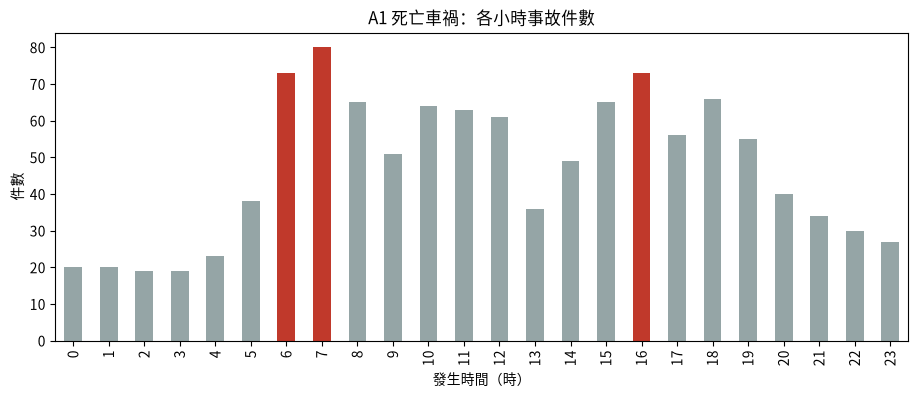

In [9]:
import matplotlib.pyplot as plt

by_hour = accidents['小時'].value_counts().sort_index()                 # 每個小時幾件事故
ax = by_hour.plot.bar(figsize=(11, 4), color=['#C0392B' if h in (6, 7, 16) else '#95A5A6' for h in by_hour.index],
                      title='A1 死亡車禍：各小時事故件數')
ax.set_xlabel('發生時間（時）'); ax.set_ylabel('件數')
plt.show()

In [10]:
causes = accidents['肇因研判子類別名稱-主要'].value_counts().head(8)
display(causes.to_frame('事故件數'))

vehicle = df['車種'].value_counts(normalize=True).mul(100).round(1).head(6)   # 所有當事者的車種占比 %
display(vehicle.to_frame('占當事者 %'))

,事故件數
肇因研判子類別名稱-主要,
恍神、緊張、心不在焉分心駕駛,199
其他不當駕車行為,161
有號誌路口，轉彎車未讓直行車先行,47
酒醉(後)駕駛,43
無號誌路口，支線道未讓幹線道先行,43
闖紅燈直行,42
左轉彎未依規定,36
車輛或機械操作不當(慎),34


,占當事者 %
車種,
機車,31.3
小客車(含客、貨兩用),21.6
非車輛（物體）,15.1
人,14.3
小貨車,5.6
慢車,3.8


> 💡 **看懂結果**：
> - **時間**：清晨 6～8 點與下午 4 點是兩個高峰，正好是**上下班、上下學**的時間。
> - **原因**：第一名是「**恍神、緊張、心不在焉分心駕駛**」，比酒駕還多！很多事故不是技術不好，而是「**沒有專心**」。
> - **車種**：死亡車禍的當事者裡，**機車騎士最多**；還有不少是行人。
>
> 所以，騎車上學時，不看手機、不趕時間、專心看路——數據告訴我們，這真的會救命。

<details><summary>🔄 想看最新資料？點我</summary>

資料每天、每月都在更新。想用今天的數字重跑一次，可以把這段程式貼到新的一格執行：

```python
import pandas as pd
url = ('https://opdadm.moi.gov.tw/api/v1/no-auth/resource/api/dataset/02D40248-7CAA-4354-82EA-E27AB8DCAB39'
       '/resource/67214307-AD41-4FE7-A04F-D8051A0301DB/download')
latest_a1 = pd.read_csv(url)                                # 警政署每隔一段時間更新今年的 A1 事故
latest_a1.shape
```

> ⚠️ 開放資料的欄位偶爾會改名或調整，如果最新資料跑出錯誤，正好練習看懂錯誤訊息、對照欄位名稱修正程式。

</details>

---

## ✍️ 換你動手：練習區

每一題都有三格：**① 半成品程式**（把 `___` 換成正確的程式）→ **② ✅ 檢查格**（自動告訴你對不對）→ **③ 🔑 參考解答**（折疊起來，先自己試）。

> 看到 `NameError: name '___' is not defined` 不用緊張，那代表還有空格沒填。

In [11]:
# @title 🧰 練習檢查小幫手（執行一次就好，不用看懂裡面的程式）
import math
import numpy as np
import pandas as pd


def _same(ans, expected, ordered=False):
    if isinstance(expected, (pd.DataFrame, pd.Series)):
        if type(ans) is not type(expected):
            return False
        try:
            assert_equal = pd.testing.assert_frame_equal if isinstance(expected, pd.DataFrame) else pd.testing.assert_series_equal
            if not ordered:
                ans, expected = ans.sort_index(), expected.sort_index()
            assert_equal(ans, expected, check_names=False, check_dtype=False,
                         check_index_type=False, check_exact=False, rtol=1e-3, atol=0.06,
                         **({'check_column_type': False} if isinstance(expected, pd.DataFrame) else {}))
            return True
        except (AssertionError, TypeError, ValueError):
            return False
    if isinstance(expected, np.ndarray):
        return np.asarray(ans).shape == expected.shape and np.allclose(np.asarray(ans, dtype=float), expected, atol=0.06)
    if isinstance(expected, (int, float, np.number)) and not isinstance(expected, bool):
        try:
            return math.isclose(float(ans), float(expected), rel_tol=1e-3, abs_tol=0.06)
        except (TypeError, ValueError):
            return False
    if isinstance(expected, (list, tuple, set)):
        return list(ans) == list(expected) if not isinstance(expected, set) else set(ans) == expected
    return ans == expected


def check(name, expected, ordered=False):
    """比對學生的變數 name 和正確答案 expected，印出 ✅ 或 ❌；ordered=True 時連排列順序也要一樣。"""
    if name not in globals():
        print(f'⏳ 還找不到變數 {name}：請先把上一格的 ___ 填好並執行')
        return
    ans = globals()[name]
    if _same(ans, expected, ordered):
        print(f'✅ {name} 答對了！')
        return
    print(f'❌ {name} 還不對，再檢查看看：')
    if type(ans) is not type(expected):
        print(f'   型態不同：你的是 {type(ans).__name__}，應該是 {type(expected).__name__}')
    elif hasattr(expected, 'shape') and getattr(ans, 'shape', None) != expected.shape:
        print(f'   大小不同：你的是 {ans.shape}，應該是 {expected.shape}')
    else:
        print('   型態和大小都對了，是數值' + ('或排列順序' if ordered else '') + '不一樣——檢查一下篩選條件或計算方式')


print('🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格')

🧰 檢查小幫手準備好了：每題寫完後，執行下方的「✅ 檢查」格


### ✍️ 練習 1：酒駕造成的死亡車禍有幾件？

<details><summary>💡 卡住了？點我看提示</summary>

用「事故表」`accidents`（一場一列）來數。主要肇因欄位是 `肇因研判子類別名稱-主要`，酒駕的寫法是 `'酒醉(後)駕駛'`。

</details>

In [ ]:
# ✏️ 練習 1：把 ___ 換成正確的程式，再按執行
drunk = (accidents['肇因研判子類別名稱-主要'] == ___).sum()
print('酒駕死亡車禍：', drunk, '件，占', round(drunk / len(accidents) * 100, 1), '%')

In [ ]:
# @title ✅ 執行這格，檢查練習 1
_acc = df[df['當事者順位'] == 1]
check('drunk', (_acc['肇因研判子類別名稱-主要'] == '酒醉(後)駕駛').sum())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
drunk = (accidents['肇因研判子類別名稱-主要'] == '酒醉(後)駕駛').sum()
print('酒駕死亡車禍：', drunk, '件，占', round(drunk / len(accidents) * 100, 1), '%')
```

</details>

### ✍️ 練習 2：哪個縣市的死亡車禍件數最多？

<details><summary>💡 卡住了？點我看提示</summary>

`accidents` 在任務 4 建立時還沒有「縣市」欄，要從 `df` 重新做一次事故表：`df[df['當事者順位'] == 1]`，再對「縣市」用 `value_counts()`。

</details>

In [ ]:
# ✏️ 練習 2：把 ___ 換成正確的程式，再按執行
acc_city = df[df['當事者順位'] == ___]['縣市'].___()
display(acc_city.head(5))

In [ ]:
# @title ✅ 執行這格，檢查練習 2
check('acc_city', df[df['當事者順位'] == 1]['縣市'].value_counts())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
acc_city = df[df['當事者順位'] == 1]['縣市'].value_counts()
display(acc_city.head(5))
# 要比較「危險程度」還要除以人口或車輛數，否則人多的縣市一定比較多
```

</details>

### ✍️ 練習 3：機車騎士的平均年齡是幾歲？

<details><summary>💡 卡住了？點我看提示</summary>

篩出 `車種 == '機車'` 的當事者，再對清理過的「年齡」欄取平均（`mean()` 會自動跳過 NaN）。

</details>

In [ ]:
# ✏️ 練習 3：把 ___ 換成正確的程式，再按執行
moto_age = df.loc[df['車種'] == ___, ___].mean()
print('死亡車禍中，機車騎士的平均年齡：', round(moto_age, 1), '歲')

In [ ]:
# @title ✅ 執行這格，檢查練習 3
check('moto_age', df.loc[df['車種'] == '機車', '年齡'].mean())

<details><summary>🔑 先自己試試看！真的想不出來再點開參考解答</summary>

```python
moto_age = df.loc[df['車種'] == '機車', '年齡'].mean()
print('死亡車禍中，機車騎士的平均年齡：', round(moto_age, 1), '歲')
```

</details>

---

## 🏆 任務完成！今天你用程式做到了這些事

- ✅ 任務 1：健康檢查——資料最後面怎麼有奇怪的東西？
- ✅ 任務 2：日期是 `20260101.0`、時間是 `53700.0`？——型態轉換
- ✅ 任務 3：「死亡1;受傷0」——把一格文字拆成兩個數字
- ✅ 任務 4：2,885 列，但其實沒有 2,885 件車禍！
- ✅ 任務 5：年齡 -1 歲？——處理異常值與缺值
- ✅ 任務 6：清乾淨了！死亡車禍最常發生在什麼時候？為什麼？

> 🎯 **帶走一句話**：程式只是工具，真正有價值的是你從資料裡找到的那句「所以我們應該……」。
> 把上面每個 💡 **看懂結果** 用自己的話寫成一句建議，就是一份可以拿去報告的分析。